In [1]:
import json

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)


In [2]:
train = pd.read_csv("data/train_set.csv", index_col=0)
val = pd.read_csv("data/val_set.csv", index_col=0)


## Shared setup

Data loading, preprocessing, and the disjoint-heads target/mask machinery
below are copied as-is from `mlp_embeddings_disjoint_embeddings.ipynb` --
no changes to any of these design decisions, only to what's varied in the
two experiments further down (data quantity, hidden layer sizes).


In [3]:
def remap_sentinel(values):
    """Undo the -2->106 convention baked into `target` (if present), then
    shift everything into a non-negative space: -2 -> 0, -1 -> 1, real
    category codes 0.. -> 2.. . Works on anything array-like (df columns,
    masks lists, tensors)."""
    values = np.asarray(values, dtype=float)
    values = np.where(values == 106, -2.0, values)
    return (values + 2).astype(np.int64)


In [4]:
continuous_fields = ['start_x', 'start_y', 'time_elapsed', 'duration']
match_state_fields = [
    'period_id', 'minute', 'second',
    'home_goal_count', 'away_goal_count',
    'home_red_count', 'away_red_count',
    'home_yellow_count', 'away_yellow_count',
]
embed_fields = ['is_home', 'event', 'result']


def with_lags(fields, n_lags=3):
    cols = list(fields)
    for lag in range(1, n_lags + 1):
        cols += [f'{f}-{lag}' for f in fields]
    return cols


continuous_cols = with_lags(continuous_fields) + match_state_fields
embed_cols = {f: [f] + [f'{f}-{lag}' for lag in range(1, 4)] for f in embed_fields}


In [5]:
def normalize_field(values, mean, std):
    """Standardize real (non-sentinel) values to mean=10, std=1; leaves -1
    (masked) and -2 (no-history) untouched, since real data is shifted
    safely away from them."""
    values = np.asarray(values, dtype=float)
    is_sentinel = (values == -1) | (values == -2)
    return np.where(is_sentinel, values, (values - mean) / std + 10)


continuous_stats = {}

for field in continuous_fields:
    cols = [field] + [f'{field}-{lag}' for lag in range(1, 4)]
    vals = train[cols].values.flatten().astype(float)
    real_vals = vals[(vals != -1) & (vals != -2)]

    continuous_stats[field] = (real_vals.mean(), real_vals.std())

for field in ['minute', 'second']:
    vals = train[field].values.astype(float)
    real_vals = vals[(vals != -1) & (vals != -2)]

    continuous_stats[field] = (real_vals.mean(), real_vals.std())


In [6]:
def build_dataset(df):
    X_cont = df[continuous_cols].values.astype(float).copy()

    for field in continuous_fields:
        mean, std = continuous_stats[field]
        for col in [field] + [f'{field}-{lag}' for lag in range(1, 4)]:
            col_idx = continuous_cols.index(col)
            X_cont[:, col_idx] = normalize_field(X_cont[:, col_idx], mean, std)

    for field in ['minute', 'second']:
        mean, std = continuous_stats[field]
        col_idx = continuous_cols.index(field)
        X_cont[:, col_idx] = normalize_field(X_cont[:, col_idx], mean, std)

    X_cont = torch.tensor(X_cont).float().contiguous()

    X_embed = {}
    for field, cols in embed_cols.items():
        X_embed[field] = torch.tensor(remap_sentinel(df[cols].values)).long().contiguous()

    Y = torch.tensor(remap_sentinel(df['target'].values)).long()

    return X_cont, X_embed, Y


In [7]:
Xtr_cont, Xtr_embed, Ytr = build_dataset(train)
Xval_cont, Xval_embed, Yval = build_dataset(val)


In [8]:
with open("data/event_masks.json") as f:
    masks = json.load(f)

masks = {col: remap_sentinel(vals).tolist() for col, vals in masks.items()}

with open("data/category_lookup.json") as f:
    lookup = json.load(f)

lookup = {
    col: {int(k): v for k, v in mapping.items()}
    for col, mapping in lookup.items()
}

event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']

output_sizes = {field: len(masks[field]) for field in event_cols}


In [9]:
step_all = torch.tensor(train["step"].values)
step_val_all = torch.tensor(val["step"].values)


In [10]:
local_target_lookups = {}

for field in event_cols:
    field_mask = torch.tensor(masks[field])
    n_classes = len(field_mask)

    pos_lookup = torch.full((108,), -1, dtype=torch.long)
    pos_lookup[field_mask] = torch.arange(n_classes)

    local_target_lookups[field] = pos_lookup


## Shared training function

One training run, parameterized by hidden layer sizes and the fraction of
train rows used -- everything else (embeddings, disjoint per-field output
heads, Kaiming-scaled init, lr schedule shape, batch size, seed) matches
`mlp_embeddings_disjoint_embeddings.ipynb` exactly, generalized from its
hardcoded 3x96 hidden stack to an arbitrary list of layer sizes.

The lr schedule keeps the same three values and the same 50%/85%
breakpoint *fractions*, scaled to whatever `max_steps` is passed in
(rather than hardcoded to 500k/850k, which assumed a 1M-step run).

Data quantity is varied via a single `manual_seed(42)` permutation of
train row indices, computed once below -- the 25%/50% subsets are the
first quarter/half of that permutation, so they're nested inside the 100%
set rather than independent random draws.

No checkpoints are saved -- these are six throwaway comparison runs, and
`MLP_EMBEDDINGS_DISJOINT_EVALUATION.md` already flags a checkpoint-path
collision from exactly this kind of ad-hoc run.


In [11]:
emb_size = 3
input_size = (emb_size * len(Xtr_embed) * 4) + Xtr_cont[0].shape[0]

train_perm = torch.randperm(Xtr_cont.shape[0], generator=torch.Generator().manual_seed(42))


def get_lr(step, max_steps):
    if step < 0.5 * max_steps:
        return 0.001
    elif step < 0.85 * max_steps:
        return 0.0001
    else:
        return 0.00001


In [12]:
def train_mlp(hidden_sizes, train_frac, max_steps=1_000_000, batch_size=1000, seed=42, eval_every=10_000):
    n_train = int(len(train_perm) * train_frac)
    sub_ix = train_perm[:n_train]

    Xsub_cont = Xtr_cont[sub_ix]
    Xsub_embed = {k: v[sub_ix] for k, v in Xtr_embed.items()}
    Ysub = Ytr[sub_ix]
    step_sub = step_all[sub_ix]

    g_eval = torch.Generator().manual_seed(42)
    n_eval = min(Xval_cont.shape[0], Xsub_cont.shape[0])
    train_eval_ix = torch.randperm(Xsub_cont.shape[0], generator=g_eval)[:n_eval]

    Xtr_eval_cont = Xsub_cont[train_eval_ix]
    Xtr_eval_embed = {k: v[train_eval_ix] for k, v in Xsub_embed.items()}
    Ytr_eval = Ysub[train_eval_ix]
    step_eval = step_sub[train_eval_ix]

    g = torch.Generator().manual_seed(seed)

    C = {}
    for field in embed_fields:
        C[field] = torch.randn((Xtr_embed[field].max() + 1, emb_size), generator=g)

    layer_sizes = [input_size] + hidden_sizes
    Ws, bs = [], []
    for i in range(len(hidden_sizes)):
        fan_in, fan_out = layer_sizes[i], layer_sizes[i + 1]
        Ws.append(torch.randn((fan_in, fan_out), generator=g) * (2 ** 0.5) / (fan_in ** 0.5))
        bs.append(torch.randn(fan_out, generator=g) * 0)

    output_heads = {}
    for field in event_cols:
        W4 = torch.randn((hidden_sizes[-1], output_sizes[field]), generator=g) * 0.001
        b4 = torch.randn(output_sizes[field], generator=g) * 0
        output_heads[field] = (W4, b4)

    parameters = list(C.values()) + Ws + bs
    for W4, b4 in output_heads.values():
        parameters += [W4, b4]
    for p in parameters:
        p.requires_grad = True

    total_params = sum(p.numel() for p in parameters)

    def forward(x_cont, x_embed):
        embs = [C[k][x_embed[k]].view(x_embed[k].shape[0], -1) for k in embed_fields]
        h = torch.cat([x_cont, *embs], dim=1)
        for W, b in zip(Ws, bs):
            h = torch.relu(h @ W + b)
        return h

    def field_loss(h, y, step_col):
        loss = 0
        for idx, field in enumerate(event_cols):
            mask = (idx == step_col)
            Xr = h[mask]
            Yr = local_target_lookups[field][y[mask]]
            W4, b4 = output_heads[field]
            logits = Xr @ W4 + b4
            loss = loss + F.cross_entropy(logits, Yr)
        return loss

    train_lossi, val_lossi = [], []

    for i in range(max_steps):
        if i % eval_every == 0:
            with torch.no_grad():
                train_lossi.append(field_loss(forward(Xtr_eval_cont, Xtr_eval_embed), Ytr_eval, step_eval).item())
                val_lossi.append(field_loss(forward(Xval_cont, Xval_embed), Yval, step_val_all).item())

        lr = get_lr(i, max_steps)
        ix = torch.randint(0, Xsub_cont.shape[0], (batch_size,), generator=g)
        Xb_cont = Xsub_cont[ix]
        Xb_embed = {k: v[ix] for k, v in Xsub_embed.items()}
        step_batch = step_sub[ix]

        h = forward(Xb_cont, Xb_embed)
        loss = field_loss(h, Ysub[ix], step_batch)

        for p in parameters:
            p.grad = None
        loss.backward()

        for p in parameters:
            p.data += -lr * p.grad

    return {
        "hidden_sizes": hidden_sizes,
        "train_frac": train_frac,
        "n_train_rows": n_train,
        "total_params": total_params,
        "max_steps": max_steps,
        "eval_every": eval_every,
        "train_lossi": train_lossi,
        "val_lossi": val_lossi,
        "final_val_loss": val_lossi[-1],
    }

## Experiment 1: does it scale with data?

Fixed architecture (3 hidden layers of 96, matching the current best
model), train quantity varied at 25% / 50% / 100% of the train set, same
1M-step budget and seed for all three runs. If the model scales with
data, val loss should decrease monotonically as `train_frac` increases.

In [13]:
data_scaling_results = []

for train_frac in [0.25, 0.5, 1.0]:
    result = train_mlp(hidden_sizes=[96, 96, 96], train_frac=train_frac)
    data_scaling_results.append(result)
    print(f"train_frac={train_frac} -> n_rows={result['n_train_rows']}, final_val_loss={result['final_val_loss']:.4f}")


train_frac=0.25 -> n_rows=1037629, final_val_loss=9.6687


train_frac=0.5 -> n_rows=2075258, final_val_loss=9.5975


train_frac=1.0 -> n_rows=4150517, final_val_loss=9.5734


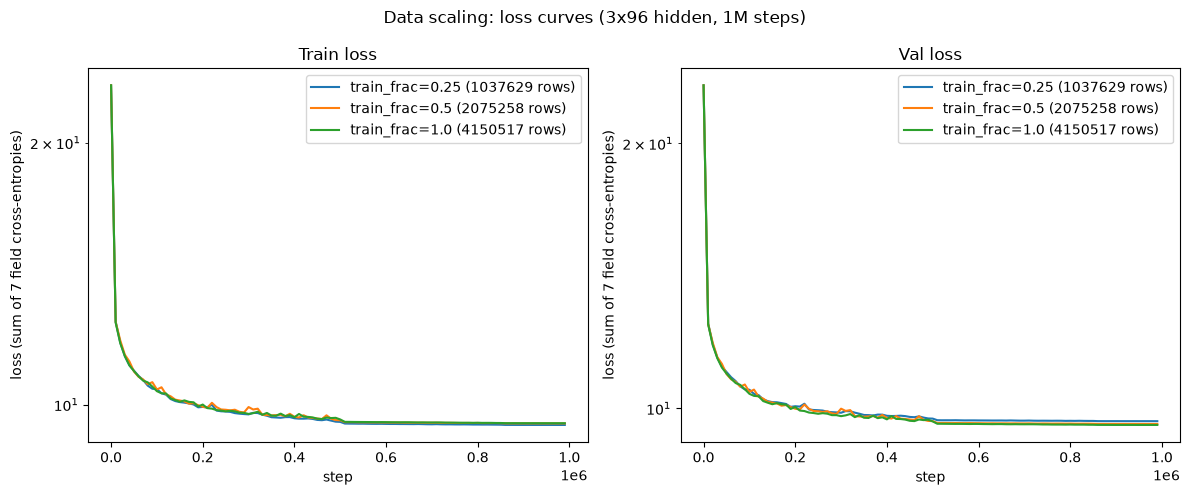

In [14]:
import os

os.makedirs("scaling_laws_results", exist_ok=True)
with open("scaling_laws_results/data_scaling_results.json", "w") as f:
    json.dump(data_scaling_results, f)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for r in data_scaling_results:
    steps = [i * r["eval_every"] for i in range(len(r["train_lossi"]))]
    label = f"train_frac={r['train_frac']} ({r['n_train_rows']} rows)"
    axes[0].plot(steps, r["train_lossi"], label=label)
    axes[1].plot(steps, r["val_lossi"], label=label)

for ax, title in zip(axes, ["Train loss", "Val loss"]):
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_ylabel("loss (sum of 7 field cross-entropies)")
    ax.set_title(title)
    ax.legend()

fig.suptitle("Data scaling: loss curves (3x96 hidden, 1M steps)")
plt.tight_layout()


,train_frac,n_train_rows,final_val_loss
0,0.25,1037629,9.668653
1,0.50,2075258,9.597486
2,1.00,4150517,9.573388


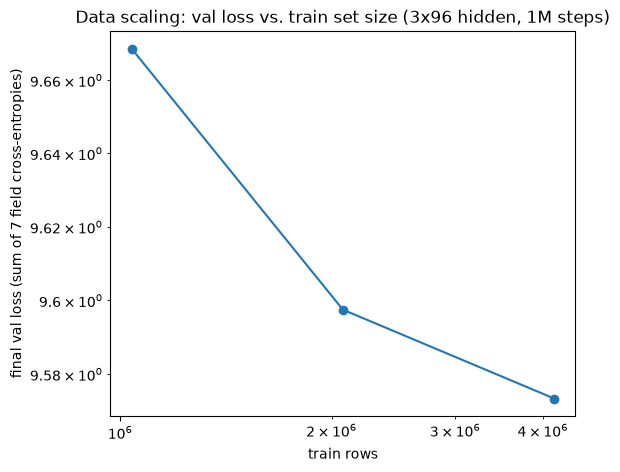

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(
    [r["n_train_rows"] for r in data_scaling_results],
    [r["final_val_loss"] for r in data_scaling_results],
    marker="o",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("train rows")
ax.set_ylabel("final val loss (sum of 7 field cross-entropies)")
ax.set_title("Data scaling: val loss vs. train set size (3x96 hidden, 1M steps)")

pd.DataFrame([
    {"train_frac": r["train_frac"], "n_train_rows": r["n_train_rows"], "final_val_loss": r["final_val_loss"]}
    for r in data_scaling_results
])

## Experiment 2: does it scale with parameters?

Full train set (100%), hidden layer sizes varied across three
architectures: `[80]`, `[96, 96]`, `[96, 96, 96]` -- the last matching
`mlp_embeddings_disjoint_embeddings.ipynb`'s current architecture. Same
1M-step budget and seed for all three runs. If the model scales with
parameters, val loss should decrease monotonically as `total_params`
increases.

In [16]:
param_scaling_results = []

for hidden_sizes in [[80], [96, 96], [96, 96, 96]]:
    result = train_mlp(hidden_sizes=hidden_sizes, train_frac=1.0)
    param_scaling_results.append(result)
    print(f"hidden_sizes={hidden_sizes} -> total_params={result['total_params']}, final_val_loss={result['final_val_loss']:.4f}")


hidden_sizes=[80] -> total_params=33748, final_val_loss=10.3895


hidden_sizes=[96, 96] -> total_params=49716, final_val_loss=9.7714


hidden_sizes=[96, 96, 96] -> total_params=59028, final_val_loss=9.5734


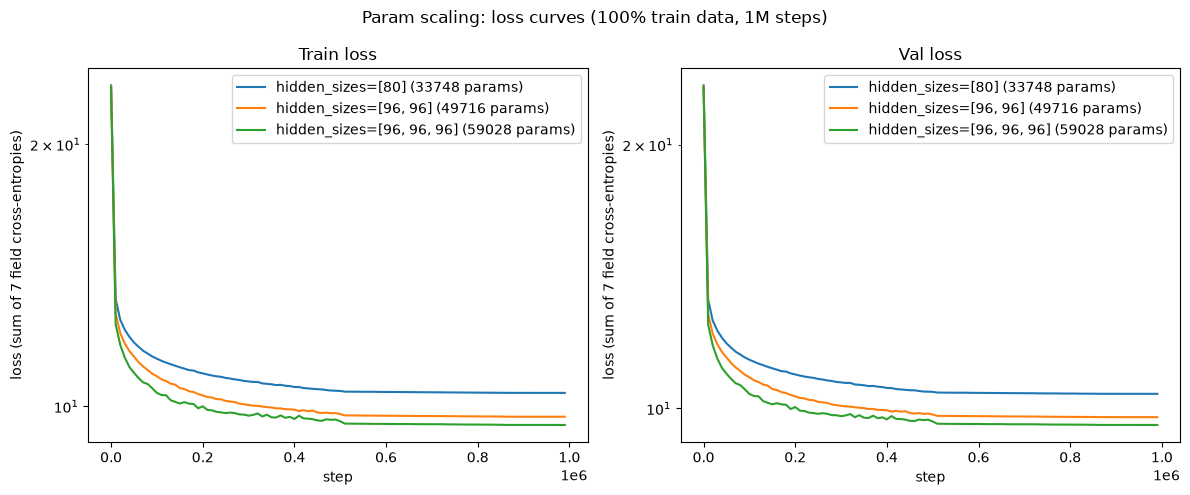

In [17]:
os.makedirs("scaling_laws_results", exist_ok=True)
with open("scaling_laws_results/param_scaling_results.json", "w") as f:
    json.dump(param_scaling_results, f)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for r in param_scaling_results:
    steps = [i * r["eval_every"] for i in range(len(r["train_lossi"]))]
    label = f"hidden_sizes={r['hidden_sizes']} ({r['total_params']} params)"
    axes[0].plot(steps, r["train_lossi"], label=label)
    axes[1].plot(steps, r["val_lossi"], label=label)

for ax, title in zip(axes, ["Train loss", "Val loss"]):
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_ylabel("loss (sum of 7 field cross-entropies)")
    ax.set_title(title)
    ax.legend()

fig.suptitle("Param scaling: loss curves (100% train data, 1M steps)")
plt.tight_layout()


,hidden_sizes,total_params,final_val_loss
0,[80],33748,10.389541
1,"[96, 96]",49716,9.771397
2,"[96, 96, 96]",59028,9.573388


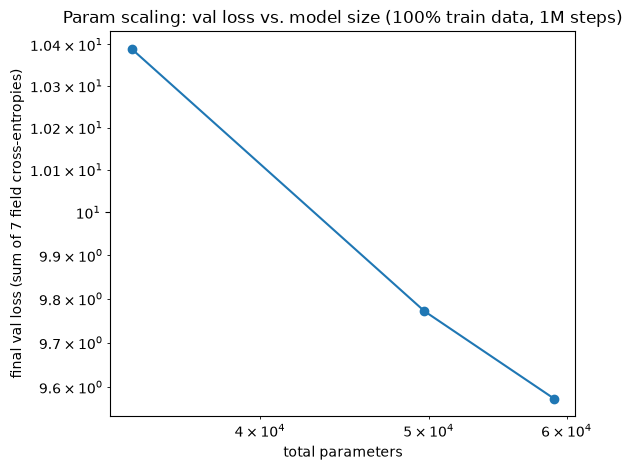

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(
    [r["total_params"] for r in param_scaling_results],
    [r["final_val_loss"] for r in param_scaling_results],
    marker="o",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("total parameters")
ax.set_ylabel("final val loss (sum of 7 field cross-entropies)")
ax.set_title("Param scaling: val loss vs. model size (100% train data, 1M steps)")

pd.DataFrame([
    {"hidden_sizes": str(r["hidden_sizes"]), "total_params": r["total_params"], "final_val_loss": r["final_val_loss"]}
    for r in param_scaling_results
])